In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
from riskhistory.setup_pupilbetas.utils_glm import build_design_matrix_run
from riskhistory.setup_pupilbetas.utils_prf import get_prf
from riskhistory.setup_pupilbetas.utils_get_data import (get_all_participants,
                                                            get_all_timings_df,
                                                            get_participant_pupil_data)
from riskhistory.setup_pupilbetas.utils_models import highpass_filter


In [2]:
sub = 3
dataset = "equalIndifference"
run = 4

In [3]:
betas = pd.read_csv("/Users/gustxsr/Documents/Stanford/PoldrackLab/github/riskhistory/results/setup_pupilbetas/pupilbetas_glm_results.csv")


In [4]:
betas

,betas_estimates,betas_names,r2,alpha,run,sub,dataset
0,-0.316489,onset-equalIndifference_sub-3_run-1,0.312948,0.372759,1,3,equalIndifference
1,-0.061601,eye_x_run-1,0.312948,0.372759,1,3,equalIndifference
2,0.006634,eye_y_run-1,0.312948,0.372759,1,3,equalIndifference
3,-0.038312,eye_x_squared_run-1,0.312948,0.372759,1,3,equalIndifference
4,-0.069330,eye_y_squared_run-1,0.312948,0.372759,1,3,equalIndifference
...,...,...,...,...,...,...,...
31454,0.106799,decision-sheng2020_sub-93_run-2_trial-198,0.306285,0.372759,2,93,sheng2020
31455,0.247692,decision-sheng2020_sub-93_run-2_trial-199,0.306285,0.372759,2,93,sheng2020
31456,-0.019408,decision-sheng2020_sub-93_run-2_trial-200,0.306285,0.372759,2,93,sheng2020
31457,0.328351,button-sheng2020_sub-93_run-2,0.306285,0.372759,2,93,sheng2020


In [18]:
decision = betas[betas['betas_names'].str.contains("decision")].copy().reset_index()
decision["trial"] = (
    decision["betas_names"]
    .str.extract(r'trial-(\d+)')
    .astype(int)
)
button = betas[betas['betas_names'].str.contains("button")].copy().reset_index()
button["trial"] = (
    button["betas_names"]
    .str.extract(r'trial-(\d+)')
    .astype(int)
)
decision = decision.rename(columns={ "betas_estimates": "decision_betas_values"})
decision = decision[["sub", "run", "dataset", "trial", "decision_betas_values"]]
button = button.rename(columns={ "betas_estimates": "button_betas_values"})
button = button[["sub", "run", "dataset", "trial", "button_betas_values"]]

button_decision = button.merge(decision, on=["sub", "run", "dataset", "trial"], how="inner")

In [32]:
# Find the correlation between button and decision betas for every sub, run, dataset
corre = button_decision.groupby(["sub", "run", "dataset"]).apply(
                                lambda df: np.corrcoef(
                                    df["button_betas_values"],
                                    df["decision_betas_values"]
                                )[0, 1]
                            ).reset_index(name="correlation")

/var/folders/xd/6fbjp5ms7ss8c4xxlmz91xkm0000gn/T/ipykernel_9943/2407021491.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corre = button_decision.groupby(["sub", "run", "dataset"]).apply(


<Axes: xlabel='correlation', ylabel='Count'>

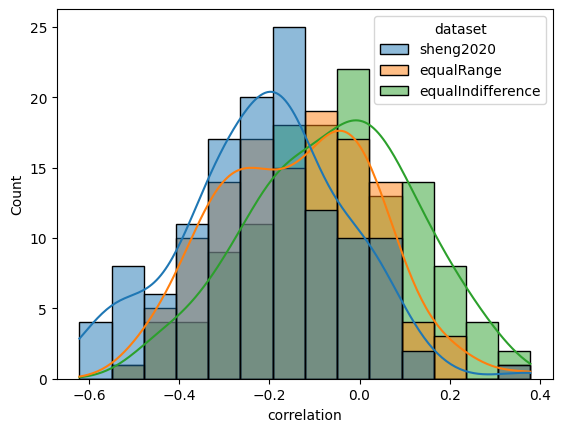

In [34]:
sns.histplot(corre, x="correlation", hue="dataset", kde=True)

In [35]:
PRF_MAX_SECS = 4
PRF_WIDTH = 10.1
PRF_TIME_TO_PEAK = 930
chosen_prf = get_prf(max_secs=PRF_MAX_SECS, width=PRF_WIDTH, time_to_peak=PRF_TIME_TO_PEAK)

In [36]:
HIGHPASS_CUTOFF = 0.05
FS = 25
ORDER = 3

In [37]:
participants, exclusions = get_all_participants()
start_timings_df = get_all_timings_df(name="start")
start_timings_df = start_timings_df.merge(participants[["dataset", "sub"]], on=["dataset", "sub"], how="inner")
chosen_prf = get_prf(max_secs=PRF_MAX_SECS, width=PRF_WIDTH, time_to_peak=PRF_TIME_TO_PEAK)

Num of valid participants for equalIndifference: 32
Num of valid participants for equalRange: 30
Num of valid participants for sheng2020: 63


In [38]:
all_pupil_data = {}
start_timings = start_timings_df.query("sub == @sub and dataset == @dataset and run == @run")
pupil_data = get_participant_pupil_data(sub, run, dataset)
pupil_data["pupil"] = highpass_filter(pupil_data["pupil_filtered"].values,
                                        cutoff=HIGHPASS_CUTOFF, fs=FS, order=ORDER)
all_pupil_data[run] = pupil_data

In [39]:
design_matrix, betas_name = build_design_matrix_run(all_pupil_data,
                                                    chosen_prf,
                                                    start_timings,
                                                    sub,
                                                    run,
                                                    dataset)

  Found 3 trials with duration < 0.1s in sub-3 run-4, setting their decision regressors to 0


(0.0, 200.0)

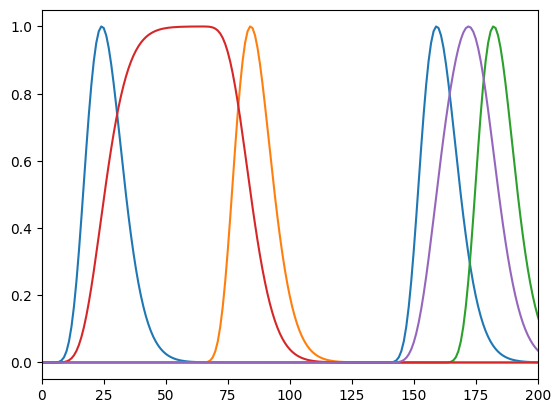

In [17]:
plt.plot(design_matrix[:, 0])
plt.plot(design_matrix[:, 70])
plt.plot(design_matrix[:, 71])
plt.plot(design_matrix[:, 6])
plt.plot(design_matrix[:, 7])
plt.xlim(0, 200)

In [ ]:
design_matrix[:, 6]


(11231, 132)

In [159]:
betas_sub = betas.query("sub == @sub and run == @run and dataset == @dataset").reset_index(drop=True)

In [160]:
for i, n in enumerate(betas_name):
    betas_val = betas_sub.query("betas_names == @n")["betas_estimates"].values[0]
    design_matrix[:, i] = design_matrix[:, i] * betas_val
pred_pupil = design_matrix.sum(axis=1)

UndefinedVariableError: name 'betas_names' is not defined

In [91]:
real_pupil = all_pupil_data[run]["pupil"].values

(70.0, 90.0)

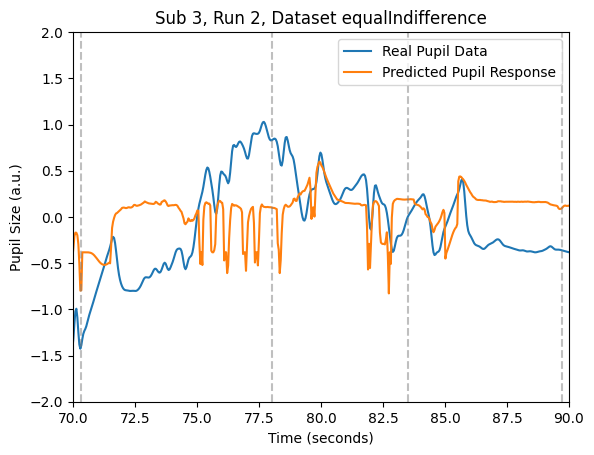

In [92]:
plt.plot(pupil_data["time_secs"], pupil_data["pupil"], label="Real Pupil Data")
plt.plot(pupil_data["time_secs"], pred_pupil, label="Predicted Pupil Response")
# place a vertical line at each anchor time
for t in start_timings["time_secs"].values:
        plt.axvline(x=t, color="gray", linestyle="--", alpha=0.5)
plt.xlabel("Time (seconds)")
plt.ylabel("Pupil Size (a.u.)")
plt.title(f"Sub {sub}, Run {run}, Dataset {dataset}")
plt.legend()
plt.ylim(-2, 2)
plt.xlim(70, 90)

In [93]:
import numpy as np
n_pre = 0
n_post = 25*2
anchor_times = start_timings["time_secs"].values
time_vec = pupil_data["time_secs"].values

In [94]:
pred_epochs = []
real_epochs = []
for t in anchor_times:
    idx = np.argmin(np.abs(time_vec - t))
    i0, i1 = idx - n_pre, idx + n_post
    if i0 >= 0 and i1 <= len(pred_pupil):
        pred_epochs.append(pred_pupil[i0:i1])
        real_epochs.append(real_pupil[i0:i1])

In [95]:
pred = np.array(pred_epochs)
real = np.array(real_epochs)

pred_mean = pred.mean(axis=0)
real_mean = real.mean(axis=0)

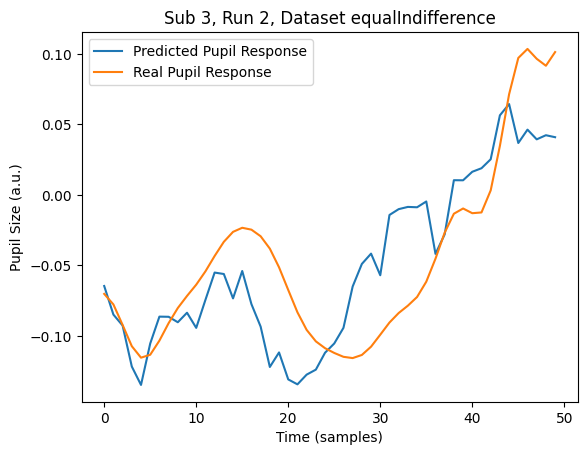

In [96]:
plt.plot(pred_mean, label="Predicted Pupil Response")
plt.plot(real_mean, label="Real Pupil Response")
plt.xlabel("Time (samples)")
plt.ylabel("Pupil Size (a.u.)")
plt.title(f"Sub {sub}, Run {run}, Dataset {dataset}")
plt.legend()
plt.show()

In [21]:
betas = pd.read_csv("/Users/gustxsr/Documents/Stanford/PoldrackLab/github/riskhistory/data/preprocessed/pupilbetas_glm_preprocessed.csv")
behavior = pd.read_csv("/Users/gustxsr/Documents/Stanford/PoldrackLab/github/riskhistory/data/preprocessed/behavioral_data.csv")

In [23]:
behavior_pupil = behavior.merge(betas, on=["sub", "run", "trial", "dataset"], how="inner")
behavior_pupil_x = behavior_pupil.query("exclude == False or exclude_startAligned == False").reset_index()

In [25]:
# make a column accept_switch that is is [accept]_[switch] 
behavior_pupil_x["accept_switch"] = behavior_pupil_x.apply(lambda row: f"{row['accept']}_{row['switch']}", axis=1)

<Axes: xlabel='dataset', ylabel='pupil'>

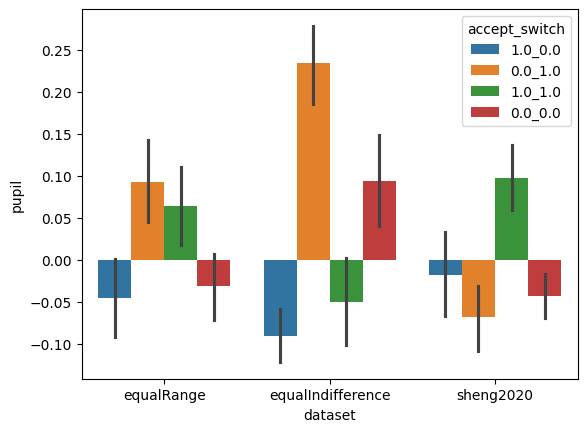

In [26]:
sns.barplot(data=behavior_pupil_x, x="dataset", y="pupil", hue="accept_switch")

In [37]:
behavior_pupil_narps = behavior_pupil.query("dataset != 'sheng2020'")

In [38]:
# make a column called strong that is 1 if response == 1 or 4 and 0 if response == 2 or 3
behavior_pupil_narps["strong"] = behavior_pupil_narps["response"].apply(lambda x: 1 if x in [1, 4] else 0)


behavior_pupil_narps["switch_strength"] = (
    behavior_pupil_narps.groupby(["sub", "run", "dataset"])["strong"]
    .transform(lambda x: np.where(x.isna() | x.shift().isna(), np.nan, (x != x.shift()).astype(float)))
)


/var/folders/xd/6fbjp5ms7ss8c4xxlmz91xkm0000gn/T/ipykernel_17528/3720803631.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  behavior_pupil_narps["strong"] = behavior_pupil_narps["response"].apply(lambda x: 1 if x in [1, 4] else 0)
/var/folders/xd/6fbjp5ms7ss8c4xxlmz91xkm0000gn/T/ipykernel_17528/3720803631.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  behavior_pupil_narps["switch_strength"] = (


In [41]:
# make a column called switch_strength_accept that is [switch_strength]_[switch]
behavior_pupil_narps["switch_strength_accept"] = behavior_pupil_narps.apply(lambda row: f"{row['switch_strength']}_{row['switch']}", axis=1)

/var/folders/xd/6fbjp5ms7ss8c4xxlmz91xkm0000gn/T/ipykernel_17528/1279519382.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  behavior_pupil_narps["switch_strength_accept"] = behavior_pupil_narps.apply(lambda row: f"{row['switch_strength']}_{row['switch']}", axis=1)


In [43]:
behavior_pupil_narps = behavior_pupil_narps.query("exclude == False or exclude_startAligned == False").reset_index(drop=True)

<Axes: xlabel='dataset', ylabel='pupil'>

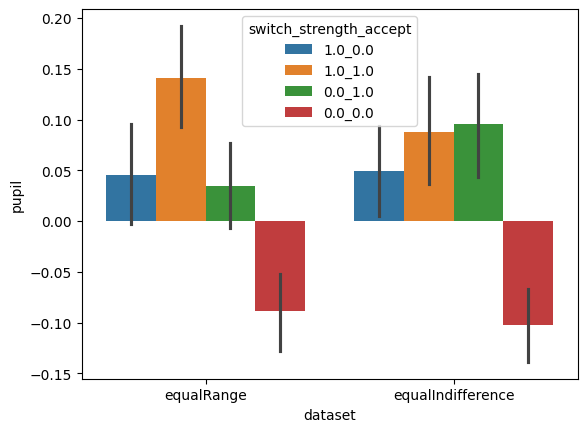

In [44]:
sns.barplot(data=behavior_pupil_narps, x="dataset", y="pupil", hue="switch_strength_accept")

In [19]:
behavior_pupil = behavior_pupil.query("dataset != 'sheng2020'")

In [20]:
behavior_pupil

,sub,trial,trial_run,run,accept,response,gain,loss,gain_centered,loss_centered,...,prev_gain,prev_loss,streak,logstreak_on_switch,logstreak_on_repeat,exclude,betas_estimates,alpha,pupil,exclude_startAligned
0,2,1,1,1,1.0,3.0,5.0,11.0,-7.5,-1.5,...,NaN,NaN,0.0,0.000000e+00,0.000000e+00,True,-0.103633,0.159986,-0.331274,True
1,2,2,2,1,1.0,4.0,20.0,9.0,7.5,-3.5,...,5.0,11.0,1.0,0.000000e+00,1.000000e-10,False,0.154196,0.159986,0.148483,True
2,2,3,3,1,0.0,2.0,8.0,13.0,-4.5,0.5,...,20.0,9.0,2.0,6.931472e-01,0.000000e+00,False,0.137294,0.159986,0.117032,False
3,2,4,4,1,1.0,3.0,14.0,9.0,1.5,-3.5,...,8.0,13.0,1.0,1.000000e-10,0.000000e+00,False,0.202142,0.159986,0.237699,False
4,2,5,5,1,0.0,1.0,8.0,18.0,-4.5,5.5,...,14.0,9.0,1.0,1.000000e-10,0.000000e+00,False,-0.268120,0.159986,-0.637345,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15611,124,252,60,4,0.0,1.0,7.0,14.0,-5.5,1.5,...,18.0,19.0,1.0,0.000000e+00,1.000000e-10,False,0.935973,0.244205,1.235805,True
15612,124,253,61,4,0.0,1.0,5.0,9.0,-7.5,-3.5,...,7.0,14.0,2.0,0.000000e+00,6.931472e-01,False,-0.105420,0.244205,-0.557786,True
15613,124,254,62,4,0.0,1.0,5.0,15.0,-7.5,2.5,...,5.0,9.0,3.0,0.000000e+00,1.098612e+00,False,1.127459,0.244205,1.565601,False
15614,124,255,63,4,0.0,1.0,12.0,18.0,-0.5,5.5,...,5.0,15.0,4.0,0.000000e+00,1.386294e+00,False,-0.940025,0.244205,-1.995227,False


In [29]:
behavior_pupil = behavior_pupil.query("exclude == False or exclude_startAligned == False").reset_index()

In [33]:
# create streak_c which is 1 2 or 3 (if greater than 3, set to 3)
behavior_pupil["streak_c"] = behavior_pupil["streak"].apply(lambda x: x if x <= 2 else 2)
# create a category rt_q (quantile within sub)
behavior_pupil["rt_q"] = behavior_pupil.groupby("sub")["rt"].transform(lambda x: pd.qcut(x, q=3, labels=False) + 1)

<Axes: xlabel='dataset', ylabel='pupil'>

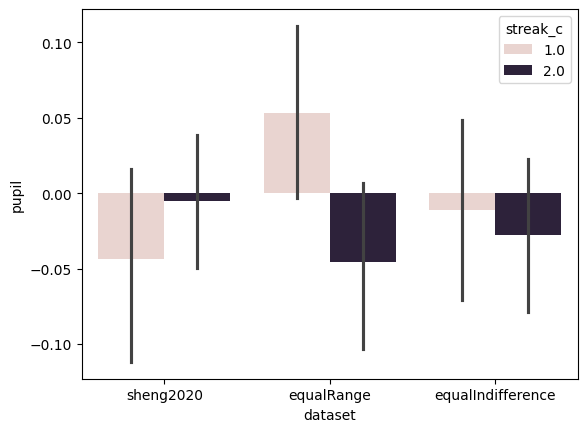

In [35]:
x = behavior_pupil.query("switch == 0").groupby(["sub", "run", "dataset", "streak_c"])["pupil"].mean().reset_index()
sns.barplot(data=x, x="dataset", y="pupil", hue="streak_c")

In [113]:
behavior_pupil.columns

Index(['sub', 'trial', 'trial_run', 'run', 'accept', 'gain', 'loss',
       'gain_centered', 'loss_centered', 'prev_gain_centered',
       'prev_loss_centered', 'rt', 'dataset', 'choice', 'choice_prev1',
       'choice_prev2', 'choice_prev3', 'choice_prev4', 'choice_prev5',
       'choice_prev6', 'switch_button', 'repeat', 'switch', 'prev_gain',
       'prev_loss', 'streak', 'logstreak_on_switch', 'logstreak_on_repeat',
       'exclude', 'betas_estimates', 'alpha', 'pupil', 'exclude_startAligned'],
      dtype='object')